# 18 · 同一系统：真实点击概率与模拟广告决策

先预测 → 只改一个变量 → 执行 → 解释。沿用同一实验记录、下载校验器、FastAPI和工作台07。

**真实部分**是 Criteo 官方曝光点击日志；**模拟部分**是单独生成的二价市场。两者没有真实收益或因果联系。日志正负抽样比例未知，模型概率只属于公开样本分布。

先预测：更复杂的树模型一定超过线性模型吗？校准一定改善 logloss 吗？恒定先验的 ECE 很小就代表有用吗？

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab.ads import latest
from reclab.paths import ARTIFACTS
receipt, result=latest()
folder=ARTIFACTS/'experiments/ads'/receipt['run_id']
print('Shared run:', receipt['run_id'])
print(result['scope'])
display(pd.DataFrame(result['splits']).T)
assert sum(x['n'] for x in result['splits'].values())==receipt['config']['rows']
print('Feature duplicate rows:',result['feature_duplicate_rows'])
print('Grouping uses features only; no temporal/user holdout is claimed.')

Shared run: 20261030T125738-f82b6582
Criteo official sampled click logs: first 200,000 rows of one 766,864-row parquet shard (2015-02-15). Real CTR task on a subsampled distribution. Auction is a separate synthetic market.


,n,positives,click_rate,unique_feature_groups
train,109935.0,3614.0,0.032874,109934.0
select,29984.0,1016.0,0.033885,29984.0
calibration,30153.0,1023.0,0.033927,30153.0
audit,29928.0,992.0,0.033146,29928.0


Feature duplicate rows: 1
Grouping uses features only; no temporal/user holdout is claimed.


## 先比较真实概率，而不是套用检索指标

AUC衡量区分度；logloss、Brier衡量概率质量。ECE采用10个等宽箱，低点击率时恒定先验也可得到很小的ECE，不能独立选型。编码器仅拟合train；select仅在80/160棵树之间选择，calibration单独拟合sigmoid和isotonic。审计不选型，线性模型仍是独立对照。

执行下面一格，观察负结果。系数全表在本机实验目录 `linear_coefficients.csv`，权重不上传。

,method,auc,logloss,brier,ece,fit_seconds
0,train_prior,0.500000,0.145515,0.032048,0.000272,0.000000
1,linear_onehot,0.721468,0.135423,0.031193,0.004382,4.102396
2,gbdt_80,0.706329,0.136029,0.031221,0.001738,0.555461
3,gbdt_160,0.703035,0.137404,0.031358,0.005350,0.932227
4,selected_sigmoid,0.706329,0.135968,0.031219,0.001149,0.008740
5,selected_isotonic,0.703064,0.136437,0.031302,0.001163,0.006879


GBDT family selected by select logloss: gbdt_80


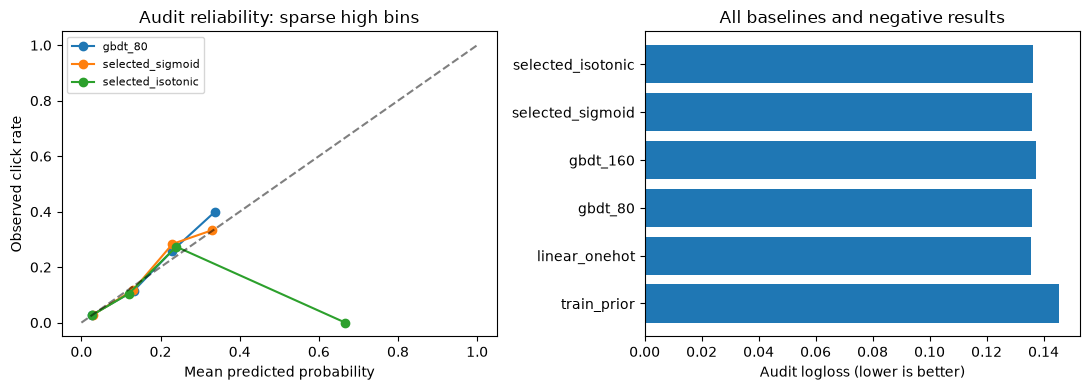

In [2]:
summary=pd.DataFrame([{'method':r['method'],**{k:r['audit'][k] for k in ['auc','logloss','brier','ece']},'fit_seconds':r['fit_seconds']} for r in result['rows']])
display(summary.round(6))
print('GBDT family selected by select logloss:',result['selected_base'])
fig,axes=plt.subplots(1,2,figsize=(11,4))
for row in result['rows']:
    if row['method'] in [result['selected_base'],'selected_sigmoid','selected_isotonic']:
        bins=row['audit']['reliability']
        axes[0].plot([b['mean_probability'] for b in bins],[b['click_rate'] for b in bins],marker='o',label=row['method'])
axes[0].plot([0,1],[0,1],'k--',alpha=.5)
axes[0].set(xlabel='Mean predicted probability',ylabel='Observed click rate',title='Audit reliability: sparse high bins')
axes[0].legend(fontsize=8)
axes[1].barh(summary.method,summary.logloss)
axes[1].set(xlabel='Audit logloss (lower is better)',title='All baselines and negative results')
fig.tight_layout()
preview=ROOT/'artifacts/notebook-previews';preview.mkdir(parents=True,exist_ok=True)
fig.savefig(preview/'18_probability.png',dpi=140)
plt.show()

## 只改一个变量：固定树模型，改变概率映射

原始分数与sigmoid使用完全相同的审计行。查看配对logloss差异及300次行bootstrap区间；区间跨零时，不能说改善已被证实。行bootstrap没有覆盖训练随机性或用户相关性。Isotonic可能在样本稀疏区过拟合并改变AUC的并列关系。

预测：缺失多和出现训练未见类别的样本，哪一段更难？先看各段点击率与样本数；这不是人口属性或公平性结论。

In [3]:
print(result['paired_sigmoid'])
display(pd.DataFrame([{'segment':s['segment'],'n':s['raw']['n'],'CTR':s['raw']['click_rate'],'raw_logloss':s['raw']['logloss'],'sigmoid_logloss':s['sigmoid']['logloss']} for s in result['segments']]))
failures=result['failures']
print('Eight highest sigmoid-loss audit exposures: clicked count =',sum(r['label'] for r in failures))
print('Detailed failure rows and all per-row predictions stay in the ignored local artifact directory.')
print('Explain: rare positive misses, missingness and unseen categories are hypotheses; anonymous features cannot establish causes.')

{'calibrated_minus_raw_logloss': -6.130390957040765e-05, 'iid_row_bootstrap_95': [-0.00016953362229380587, 6.253575759107997e-05], 'replicates': 300, 'limitation': 'conditional on fitted models; repeated/related rows and one shard limit independence and generalization'}


,segment,n,CTR,raw_logloss,sigmoid_logloss
0,low_numeric_missing,17016,0.036495,0.147043,0.146935
1,high_numeric_missing,12912,0.028733,0.121515,0.121515
2,any_unseen_category,11668,0.035996,0.146929,0.146712
3,all_categories_seen,18260,0.031325,0.129065,0.129103


Eight highest sigmoid-loss audit exposures: clicked count = 8
Detailed failure rows and all per-row predictions stay in the ignored local artifact directory.
Explain: rare positive misses, missingness and unseen categories are hypotheses; anonymous features cannot establish causes.


## 只改一个变量：同一模拟市场的出价倍数

以下不是Criteo回放。3个虚构广告主，6000次请求，独立生成真实点击概率、带噪估计概率和所有潜在点击；后半程流量更有价值。报价单位为“每曝光货币”，得分是估计点击率×虚构点击价值；赢家支付次高报价（含外部竞争价）。每广告主预算60。

先预测：固定seed、预算和pacing，仅将倍数从1降为0.5，会少花钱还是赢得不同曝光？再解释累计花费曲线。合成市场中的后半程优势是构造假设，不能据此发布生产出价策略。

,policy,spend,expected_click_value,expected_advertiser_surplus,clicks,budget_ok
0,bid x1,179.352946,363.687988,184.335042,181,True
1,bid x0.5,179.667495,594.607116,414.939622,297,True


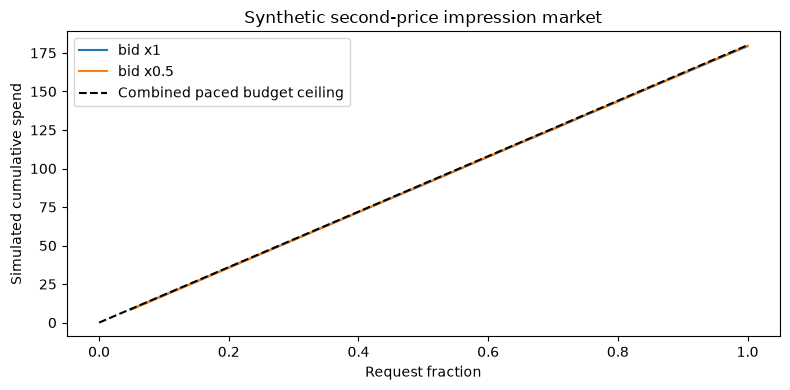

All fixed-seed policies:


,policy,seed,simulated_revenue,expected_value,budget_ok
0,flat,41,179.946768,310.260151,True
1,value,41,179.954436,312.713379,True
2,value_paced,41,179.523495,362.738625,True
3,value_paced_halfbid,41,179.584778,588.807349,True
4,flat,42,179.958459,320.400544,True
5,value,42,179.950958,325.099130,True
6,value_paced,42,179.352946,363.687988,True
7,value_paced_halfbid,42,179.667495,594.607116,True
8,flat,43,179.880956,302.367394,True
9,value,43,179.955613,328.793557,True


In [4]:
from reclab.auction import market, simulate
synthetic=market(seed=42)
controls=[('bid x1',simulate(synthetic,multiplier=1.,paced=True)),('bid x0.5',simulate(synthetic,multiplier=.5,paced=True))]
display(pd.DataFrame([{'policy':name,**{k:r[k] for k in ['spend','expected_click_value','expected_advertiser_surplus','clicks','budget_ok']}} for name,r in controls]))
fig,ax=plt.subplots(figsize=(8,4))
for name,r in controls:
    ax.plot([t['fraction'] for t in r['trace']],[sum(t['spend']) for t in r['trace']],label=name)
    assert r['budget_ok']
    assert all(max(t['spend'])<=60*t['fraction']+1e-8 for t in r['trace'])
ax.plot([0,1],[0,180],'k--',label='Combined paced budget ceiling')
ax.set(xlabel='Request fraction',ylabel='Simulated cumulative spend',title='Synthetic second-price impression market')
ax.legend();fig.tight_layout();fig.savefig(preview/'18_market.png',dpi=140);plt.show()
print('All fixed-seed policies:')
display(pd.DataFrame([{'policy':r['name'],'seed':r['seed'],'simulated_revenue':r['spend'],'expected_value':r['expected_click_value'],'budget_ok':r['budget_ok']} for r in result['simulations']]))

## 解释并回到共享系统

本轮线性模型胜过两个小树模型；sigmoid的小幅改善不确定，isotonic没有胜出。恒定先验的低ECE不能替代区分度和适当评分。模拟pacing和半价出价只说明预设市场中的资源分配，所有广告主同时改变报价、外部竞价不变、请求价值随时间增长等假设限制结论。

[工作台07](http://127.0.0.1:18580)可修改匿名特征并实际调用训练模型，也可独立调整模拟市场预算。训练需显式执行 `python -m reclab.ads --download`，每次创建新记录，不覆盖旧模型。详细来源与边界见 `docs/ADS_EXPERIMENTS.md`。没有完成全量Criteo、线上校准、反事实收益评估或论文完整复现。